In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import uproot
import matplotlib.gridspec as gridspec

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins, weights, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    for i in range(1, len(bins)):
        #print(bins[i] - bins[i-1])
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])
        
    if density:
        hist /= weights.sum()
        errs /= weights.sum()
    
    return hist, errs, bins

In [5]:
# prepare dataframe for data
observables1 = ['pt','m','q','rg','zg','mg','n']
observabless1 = ['pts','ms','qs','rgs','zgs','mgs','ns']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data062824.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']), np.concatenate(tree['m']), np.concatenate(tree['q']), np.concatenate(tree['rg']), np.concatenate(tree['zg']), np.concatenate(tree['mg']), np.concatenate(tree['n'])))), columns=observabless1)

In [6]:
# embedding 2023 (full sample)
observables2 = ['pt','m','q','rg','zg','mg','w','mcevi','n']
observabless2 = ['pts','ms','qs','rgs','zgs','mgs','ns']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.root']
treeName = ["MatchedTree"]
df4 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), 'pts>15 and w<1')

In [12]:
binedges = np.arange(1.5, 25.5)
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

In [8]:
plt.rcParams['font.size'] = 15

In [17]:
min(df4['ns'])

1

(1.5, 24.5)

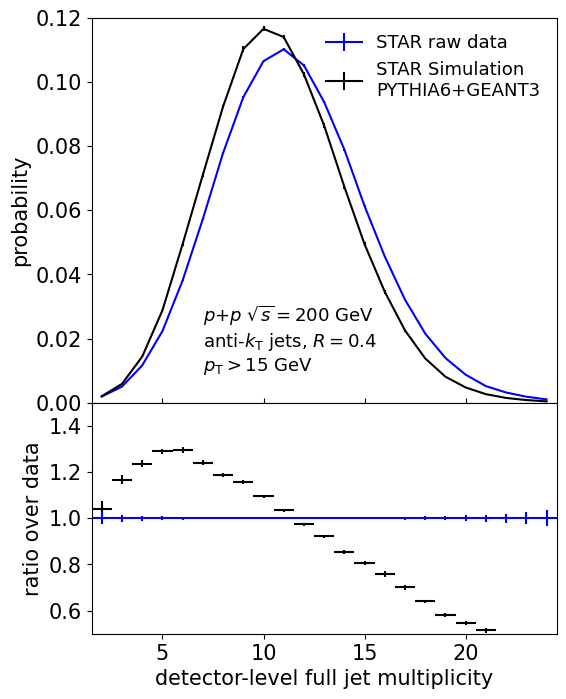

In [23]:
gs = gridspec.GridSpec(2, 1, height_ratios=(5,3))
fig = plt.figure(figsize=(6,8))
plt.subplots_adjust(wspace=0, hspace=0)
    
ax1 = fig.add_subplot(gs[0])
y4, yerr4 = calc_hist(df4['ns'], bins=binedges, weights=df4['w'], density=True)[:2]
y_data, yerr_data = calc_hist(df_data['ns'], bins=binedges, weights=np.ones(df_data.shape[0]), density=True)[:2]
plt.errorbar(x, y_data, yerr=yerr_data, color='b', label='STAR raw data')
plt.errorbar(x, y4, yerr=yerr4, color='k', label='STAR Simulation\nPYTHIA6+GEANT3')
plt.legend(loc='upper right', fontsize=13, frameon=False)
plt.text(7, 0.01,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>15$ GeV', fontsize=13)
plt.ylabel('probability')
plt.ylim(0,0.12)
plt.xlim(1.5,24.5)
ax1.tick_params(axis="x",direction="in")
ax1.set_xticklabels([])

ax2 = fig.add_subplot(gs[1])
plt.errorbar(x, y4/y_data, xerr=binedges[1:]-x, yerr=yerr4/y_data, color='k', ls='none')
plt.errorbar(x, np.ones(len(y_data)), xerr=binedges[1:]-x, yerr=yerr_data/y_data, color='b', ls='none')
plt.ylabel("ratio over data")
plt.xlabel("detector-level full jet multiplicity")
plt.ylim(0.5, 1.5)
plt.xlim(1.5,24.5)

In [11]:
print(x)
print(y4/y_data)

[2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5, 11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5, 22.5, 23.5, 24.5]
[1.03975276 1.16700534 1.23559037 1.28954171 1.29708761 1.24031264
 1.1861093  1.15743956 1.09456191 1.03455006 0.97354676 0.92161257
 0.85297302 0.80557142 0.75876452 0.70186709 0.6404636  0.58145423
 0.5449523  0.51536246 0.46744694 0.44093856 0.42061433]


In [15]:
print(x)
print(y4/y_data)

[2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0]
[1.03975276 1.16700534 1.23559037 1.28954171 1.29708761 1.24031264
 1.1861093  1.15743956 1.09456191 1.03455006 0.97354676 0.92161257
 0.85297302 0.80557142 0.75876452 0.70186709 0.6404636  0.58145423
 0.5449523  0.51536246 0.46744694 0.44093856 0.41295937]


In [7]:
df_data = applyCut(df_data, 'ms > 1')
df4 = applyCut(df4, 'ms > 1')

In [9]:
observables2 = ['pt','m','q','rg','zg','mg','w','mcevi','n']
observabless2 = ['pts','ms','qs','rgs','zgs','mgs','ns']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0901.root']
treeName = ["MatchedTree"]
df1 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), 'pts>15 and w<1 and ms>1')

In [10]:
binedges = np.arange(2, 26)
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

In [11]:
plt.rcParams['font.size'] = 15

(0.5, 1.5)

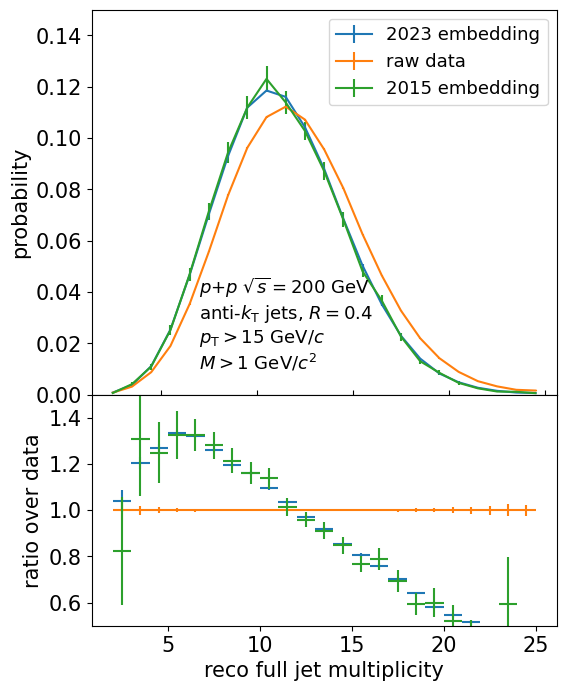

In [16]:
gs = gridspec.GridSpec(2, 1, height_ratios=(5,3))
fig = plt.figure(figsize=(6,8))
plt.subplots_adjust(wspace=0, hspace=0)
    
ax1 = fig.add_subplot(gs[0])
y4, yerr4 = calc_hist(df4['ns'], bins=binedges, weights=df4['w'], density=True)[:2]
y_data, yerr_data = calc_hist(df_data['ns'], bins=binedges, weights=np.ones(df_data.shape[0]), density=True)[:2]
y1, yerr1 = calc_hist(df1['ns'], bins=binedges, weights=df1['w'], density=True)[:2]
plt.errorbar(x, y4, yerr=yerr4, label='2023 embedding')
plt.errorbar(x, y_data, yerr=yerr_data, label='raw data')
plt.errorbar(x, y1, yerr=yerr1, label='2015 embedding')
plt.legend(loc='upper right', fontsize=13)
plt.text(7, 0.01,'$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>15$ GeV$/c$\n$M>1$ GeV$/c^2$', fontsize=13)
plt.ylabel('probability')
plt.ylim(0,0.15)
plt.xticks(np.arange(5,30,5))
ax1.tick_params(axis="x",direction="in")

ax2 = fig.add_subplot(gs[1])
plt.errorbar(x, y4/y_data, xerr=binedges[1:]-x, yerr=yerr4/y_data, ls='none')
plt.errorbar(x, np.ones(len(y_data)), xerr=binedges[1:]-x, yerr=yerr_data/y_data, ls='none')
plt.errorbar(x, y1/y_data, xerr=binedges[1:]-x, yerr=yerr1/y_data, ls='none')
plt.ylabel("ratio over data")
plt.xlabel("reco full jet multiplicity")
plt.ylim(0.5, 1.5)